# User Behavior Anomaly Detection for Cybersecurity - 2
### Isolation Forest for Login Behavior Analysis - Login Risk and Account Takeover

**Author:** MiyukiMol  
**Target roles:** Data Scientist · Security Analytics · Threat Detection  
**Tools:** Python, pandas, NumPy, scikit-learn, Matplotlib, Seaborn, Google Colab  
**Dataset:** [Login Data Set for Risk-Based Authentication (RBA)](https://www.kaggle.com/datasets/dasgroup/rba-dataset)


---



## 1. Project Overview

### 1.1 Business Context

In cybersecurity, detecting suspicious login activity is challenging because confirmed attack labels are often limited or unavailable.

Traditional supervised machine learning requires labelled examples to learn the difference between legitimate and malicious activity.

Unsupervised anomaly detection offers an alternative approach by identifying unusual patterns without requiring attack labels during model training.

### 1.2 Project Objective

The objective of this notebook is to implement an Isolation Forest model to identify potentially anomalous login events.

The model will learn patterns in login behavior and assign anomaly scores to individual events.

### 1.3 Research Questions

- Can Isolation Forest identify unusual login behavior?
- Which login characteristics are associated with detected anomalies?
- How do detected anomalies compare with known account-takeover labels?
- What are the limitations of unsupervised anomaly detection in cybersecurity?

### 1.4 Notebook Structure

This notebook follows a structured unsupervised anomaly detection workflow:

1. **Project Overview** — Project objectives and business context
2. **Environment Setup** — Importing libraries and configuring the environment
3. **Dataset Loading** — Loading the dataset
4. **Data Preparation** — Data inspection and preparation
5. **Feature Engineering** — Creating features for anomaly detection
6. **Data Preprocessing** — Handling missing values and encoding categorical variables
7. **Train Isolation Forest** — Training the unsupervised anomaly detection model
8. **Anomaly Detection** — Generating anomaly scores and identifying unusual login events
9. **Model Evaluation** — Comparing detected anomalies with account-takeover labels
10. **Feature Analysis** — Analyzing the characteristics of detected anomalies
11. **Key Findings** — Summarizing results and limitations
12. **Conclusion and Next Steps** — Discussing improvements and future work

### 1.5 Important Considerations

The `Is Account Takeover` column will be excluded from model training and used only for post-training evaluation.

An anomaly does not necessarily represent a cyberattack. It indicates behavior that differs from the patterns learned by the model.

## 2 - Environment Setup

### 2.1 Import Libraries

In [ ]:
# 2.1 Import Libraries

# Data manipulation
import pandas as pd
import numpy as np
import os
import zipfile
from getpass import getpass

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning and preprocessing
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Model evaluation
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

# Utilities
import warnings
import random

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("Libraries imported successfully.")
print("Random state:", RANDOM_STATE)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully.
Random state: 42
Pandas version: 2.2.3
NumPy version: 2.4.6


### 2.2 Environment Configuration

A fixed random state is used to improve reproducibility across experiments.

The visualization settings are configured to make charts easier to interpret.

The following configuration will be used throughout this notebook:

- **Random state:** 42
- **Visualization style:** Seaborn whitegrid
- **Machine learning library:** Scikit-learn

## 3 - Dataset Acquisition and Loading

This project uses the Login Data Set for Risk-Based Authentication (RBA) from Kaggle.

The dataset contains approximately 31.27 million login events, including login timestamps, user identifiers, login outcomes, device information, geographical information, and account-takeover labels.

A major challenge is the extreme class imbalance: only 141 events are labelled as account takeovers.

Therefore, this notebook uses a memory-efficient data-loading strategy to preserve rare positive cases while preparing data for unsupervised anomaly detection.

**Dataset source:** [Login Data Set for Risk-Based Authentication (RBA)](https://www.kaggle.com/datasets/dasgroup/rba-dataset)

### 3.1 Install Kaggle CLI

we will download the "**Login Data Set for Risk-Based Authentication**" dataset from Kaggle and load a manageable sample without extracting the entire large CSV to disk.

https://www.kaggle.com/datasets/dasgroup/rba-dataset

In [ ]:
# Install the Kaggle CLI in the current Colab runtime.
%pip -q install kaggle

### 3.2 Configure Kaggle API Credentials

In [ ]:
# Enter the Kaggle API token without displaying it.
# For a public portfolio, consider using Google Colab Secrets instead.
kaggle_token = getpass("Paste your Kaggle API token: ")
os.environ["KAGGLE_API_TOKEN"] = kaggle_token

Paste your Kaggle API token: ··········


### 3.3 Download the Dataset

In [ ]:
# Download the dataset ZIP.
!kaggle datasets download -d dasgroup/rba-dataset -p /content

Dataset URL: https://www.kaggle.com/datasets/dasgroup/rba-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
100% 1.10G/1.10G [00:15<00:00, 78.2MB/s]



### 3.4 Verify the Downloaded ZIP Archive

In [ ]:
ZIP_PATH = "/content/rba-dataset.zip"

# Check whether the ZIP file exists
if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(
        "Dataset ZIP file was not found. Please check the download step."
    )

# Verify that the file is a valid ZIP archive
if not zipfile.is_zipfile(ZIP_PATH):
    raise ValueError("The downloaded file is not a valid ZIP archive.")

file_size_gb = os.path.getsize(ZIP_PATH) / (1024 ** 3)

print("ZIP archive verified successfully.")
print(f"File path: {ZIP_PATH}")
print(f"File size: {file_size_gb:.2f} GB")

ZIP archive verified successfully.
File path: /content/rba-dataset.zip
File size: 1.10 GB


### 3.5 Identify the CSV File

In [ ]:
with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    csv_files = [
        name for name in archive.namelist()
        if name.lower().endswith(".csv")
    ]

    if not csv_files:
        raise FileNotFoundError(
            "No CSV file was found in the ZIP archive."
        )

    print("CSV file(s) found:")

    for csv_file in csv_files:
        print(f"- {csv_file}")

if len(csv_files) > 1:
    raise ValueError(
        "Multiple CSV files found. Please identify the correct dataset."
    )

CSV_NAME = csv_files[0]

print(f"\nSelected CSV file: {CSV_NAME}")

CSV file(s) found:
- rba-dataset.csv

Selected CSV file: rba-dataset.csv


### 3.6 Inspect the Dataset Structure

In [ ]:
with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    with archive.open(CSV_NAME) as file:
        df_preview = pd.read_csv(file, nrows=5)

print(f"Preview shape: {df_preview.shape}")

print("\nColumn names:")
print(df_preview.columns.tolist())

print("\nData types:")
print(df_preview.dtypes)

display(df_preview)

Preview shape: (5, 16)

Column names:
['index', 'Login Timestamp', 'User ID', 'Round-Trip Time [ms]', 'IP Address', 'Country', 'Region', 'City', 'ASN', 'User Agent String', 'Browser Name and Version', 'OS Name and Version', 'Device Type', 'Login Successful', 'Is Attack IP', 'Is Account Takeover']

Data types:
index                         int64
Login Timestamp              object
User ID                       int64
Round-Trip Time [ms]        float64
IP Address                   object
Country                      object
Region                       object
City                         object
ASN                           int64
User Agent String            object
Browser Name and Version     object
OS Name and Version          object
Device Type                  object
Login Successful               bool
Is Attack IP                   bool
Is Account Takeover            bool
dtype: object


,index,Login Timestamp,User ID,Round-Trip Time [ms],IP Address,Country,Region,City,ASN,User Agent String,Browser Name and Version,OS Name and Version,Device Type,Login Successful,Is Attack IP,Is Account Takeover
0,0,2020-02-03 12:43:30.772,-4324475583306591935,NaN,10.0.65.171,NO,-,-,29695,Mozilla/5.0 (iPhone; CPU iPhone OS 13_4 like ...,Firefox 20.0.0.1618,iOS 13.4,mobile,False,False,False
1,1,2020-02-03 12:43:43.549,-4324475583306591935,NaN,194.87.207.6,AU,-,-,60117,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile 46.0.2490,Android 4.1,mobile,False,False,False
2,2,2020-02-03 12:43:55.873,-3284137479262433373,NaN,81.167.144.58,NO,Vestland,Urangsvag,29695,Mozilla/5.0 (iPad; CPU OS 7_1 like Mac OS X) ...,Android 2.3.3.2672,iOS 7.1,mobile,True,False,False
3,3,2020-02-03 12:43:56.180,-4324475583306591935,NaN,170.39.78.152,US,-,-,393398,Mozilla/5.0 (Linux; Android 4.1; Galaxy Nexus...,Chrome Mobile WebView 85.0.4183,Android 4.1,mobile,False,False,False
4,4,2020-02-03 12:43:59.396,-4618854071942621186,NaN,10.0.0.47,US,Virginia,Ashburn,398986,Mozilla/5.0 (Linux; U; Android 2.2) Build/NMA...,Chrome Mobile WebView 85.0.4183,Android 2.2,mobile,False,True,False


### 3.7 Summary

The dataset has been successfully downloaded, verified, and inspected.

The initial preview contains 5 rows and 16 columns, including user identifiers, login timestamps, IP addresses, geographic information, device details, login outcomes, and security-related labels.

The dataset contains both numerical and categorical features, as well as Boolean variables.

The following observations were identified:

- `Login Timestamp` is initially stored as an object and will need datetime conversion.
- `User ID` is stored as an integer and can be used to identify user-related login patterns.
- `Login Successful`, `Is Attack IP`, and `Is Account Takeover` are Boolean variables.
- `Is Account Takeover` will be used as the evaluation target, not as an input feature during model training.
- `Is Attack IP` requires careful consideration to avoid potential data leakage.
- Some geographic fields contain placeholder values such as `-`, which will require further inspection during data preparation.

Since the dataset is large, we will use chunk-based processing in the next section to reduce memory consumption.

In the next section, we will prepare the dataset for unsupervised anomaly detection.



---



## 4 - Data Preparation

In this section, we prepare the dataset for unsupervised anomaly detection.

Since the original dataset contains millions of login events, we use chunk-based processing to reduce memory consumption.

We retain all Account Takeover (ATO) events and randomly sample a subset of non-ATO events for analysis.

The target label is kept separate from the input features to prevent data leakage.

### 4.1 Define Target and Feature Columns

We identify the target variable and select the initial features required for anomaly detection.

The `Is Account Takeover` column is reserved for model evaluation and will not be used during model training.

We initially select login-related and user-related information. Additional features will be engineered in a later section.

In [ ]:
TARGET_COLUMN = "Is Account Takeover"

FEATURE_COLUMNS = [
    "User ID",
    "Login Timestamp",
    "Login Successful",
    "Country",
    "Device Type"
]

USE_COLUMNS = FEATURE_COLUMNS + [TARGET_COLUMN]

print("Target column:", TARGET_COLUMN)
print("\nSelected feature columns:")
print(FEATURE_COLUMNS)

Target column: Is Account Takeover

Selected feature columns:
['User ID', 'Login Timestamp', 'Login Successful', 'Country', 'Device Type']


### 4.2 Load and Sample the Dataset Using Chunk-based Random Sampling

To manage the large dataset efficiently, we use **Chunk-based Random Sampling** instead of loading the entire dataset into memory.

The CSV file is processed in chunks of 100,000 rows. Within each chunk, all positive Account Takeover (ATO) events are retained, while approximately 1% of negative events are randomly selected.

The sampled negative events from all chunks are then combined and limited to a maximum of 200,000 records.

This approach reduces memory consumption and computational overhead while obtaining randomly selected negative events from across the dataset.

The target label (`Is Account Takeover`) is used only to distinguish positive and negative events during sampling and for subsequent model evaluation. It is excluded from the input features used to train the unsupervised anomaly detection model.

Since this sampling strategy changes the original class distribution, evaluation metrics must be interpreted with this limitation in mind.

In [ ]:
CHUNK_SIZE = 100_000
MAX_NEGATIVE_SAMPLES = 200_000

positive_chunks = []
negative_chunks = []

total_rows = 0

with zipfile.ZipFile(ZIP_PATH, "r") as archive:

    with archive.open(CSV_NAME) as file:

        for chunk_number, chunk in enumerate(
            pd.read_csv(
                file,
                usecols=USE_COLUMNS,
                chunksize=CHUNK_SIZE
            )
        ):

            total_rows += len(chunk)

            # Keep all positive ATO events
            positive = chunk[chunk[TARGET_COLUMN] == True]

            if not positive.empty:
                positive_chunks.append(positive)

            # Randomly sample negative events from each chunk
            negative = chunk[chunk[TARGET_COLUMN] == False]

            sampled_negative = negative.sample(
                frac=0.01,
                random_state=RANDOM_STATE + chunk_number
            )

            if not sampled_negative.empty:
                negative_chunks.append(sampled_negative)

# Combine all positive events
positive_df = pd.concat(
    positive_chunks,
    ignore_index=True
)

# Combine sampled negative events
negative_df = pd.concat(
    negative_chunks,
    ignore_index=True
)

# Limit the negative sample to 200,000 rows
if len(negative_df) > MAX_NEGATIVE_SAMPLES:
    negative_df = negative_df.sample(
        n=MAX_NEGATIVE_SAMPLES,
        random_state=RANDOM_STATE
    ).reset_index(drop=True)

# Combine positive and negative events
df = pd.concat(
    [positive_df, negative_df],
    ignore_index=True
)

print("Dataset sampling completed.")
print(f"Total rows scanned: {total_rows:,}")
print(f"Positive ATO events: {len(positive_df):,}")
print(f"Negative events sampled: {len(negative_df):,}")
print(f"Final dataset shape: {df.shape}")

Dataset sampling completed.
Total rows scanned: 31,269,264
Positive ATO events: 141
Negative events sampled: 200,000
Final dataset shape: (200141, 6)


### 4.3 Validate the Sampled Dataset

After sampling, we validate the resulting dataset to ensure that it is suitable for further analysis.

The validation includes:

- Checking the dataset dimensions.
- Inspecting the distribution of the target variable.
- Checking for missing values.
- Checking for duplicate records.
- Reviewing the memory usage.

These checks help identify potential data quality issues before feature engineering and preprocessing.

In [ ]:
# Check dataset dimensions
print("Dataset shape:", df.shape)

# Check target distribution
print("\nTarget distribution:")
print(df[TARGET_COLUMN].value_counts())

# Check target distribution in percentage
print("\nTarget distribution (%):")
print(
    (df[TARGET_COLUMN].value_counts(normalize=True) * 100)
    .round(4)
)

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Check memory usage
memory_usage_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
print(f"\nMemory usage: {memory_usage_mb:.2f} MB")

Dataset shape: (200141, 6)

Target distribution:
Is Account Takeover
False    200000
True        141
Name: count, dtype: int64

Target distribution (%):
Is Account Takeover
False    99.9295
True      0.0705
Name: proportion, dtype: float64

Missing values:
Login Timestamp        0
User ID                0
Country                0
Device Type            5
Login Successful       0
Is Account Takeover    0
dtype: int64

Number of duplicate rows: 0

Memory usage: 35.90 MB


#### 4.3.1 Interpretation
- Class imbalance: ATO events account for approximately 0.0705% of the total. This is higher than the original data's ~0.00045%, which is due to sampling the Negative events.

- Missing values: There are 5 missing values in the "Device Type" column.

- Duplicates: There are no duplicate rows.

- Memory: At approximately 35.90 MB, the sample size this time is relatively easy to work with.

### 4.4 Handle Missing Values and Convert Data Types

Before feature engineering, we handle missing values and ensure that each column has an appropriate data type.

The `Device Type` column contains a small number of missing values. These are replaced with `"Unknown"` to preserve the corresponding login events without introducing an unsupported device category.

The `Login Timestamp` column is converted from an object to a datetime format to support time-based feature engineering.

Finally, the dataset is checked again to verify that the changes were applied correctly.

In [ ]:
# Replace missing device types
df["Device Type"] = df["Device Type"].fillna("unknown")

# Convert login timestamps to datetime
df["Login Timestamp"] = pd.to_datetime(
    df["Login Timestamp"],
    errors="coerce"
)

# Verify data types
print("Updated data types:")
print(df.dtypes)

# Check missing values again
print("\nMissing values after handling:")
print(df.isnull().sum())

# Check dataset dimensions
print("\nDataset shape:", df.shape)

Updated data types:
Login Timestamp        datetime64[ns]
User ID                         int64
Country                        object
Device Type                    object
Login Successful                 bool
Is Account Takeover              bool
dtype: object

Missing values after handling:
Login Timestamp        0
User ID                0
Country                0
Device Type            0
Login Successful       0
Is Account Takeover    0
dtype: int64

Dataset shape: (200141, 6)


#### 4.4.4 Interpretation

- `Login Timestamp` was converted to `datetime64[ns]`.
- 5 missing values in `Device Type` were replaced with "unknown".
- There are now 0 missing values across all columns.
- The number of data records remains unchanged at 200,141.

In [ ]:
df["Device Type"].unique()

array(['desktop', 'mobile', 'tablet', 'bot', 'unknown'], dtype=object)

### 4.5 Sort Events Chronologically

The sampled dataset contains positive and negative events that were collected separately and then combined.

As a result, the records are not necessarily in chronological order.

We sort the dataset by `Login Timestamp` to restore the chronological order of login events.

This step is important for subsequent time-based feature engineering and for preventing temporal data leakage during model evaluation.

Since positive and negative events were grouped separately and then concatenated in 4.2, the current `df` is not in the original chronological order. Let's sort the login events in chronological order.

In [ ]:
# Sort login events by timestamp
df = df.sort_values(
    by="Login Timestamp"
).reset_index(drop=True)

# Verify chronological order
print("Earliest login:", df["Login Timestamp"].min())
print("Latest login:", df["Login Timestamp"].max())

# Check whether timestamps are sorted
is_sorted = df["Login Timestamp"].is_monotonic_increasing

print("\nChronological order:", is_sorted)

# Display the first five records
display(df.head())

Earliest login: 2020-02-03 12:45:35.586000
Latest login: 2021-02-28 23:52:04.617000

Chronological order: True


,Login Timestamp,User ID,Country,Device Type,Login Successful,Is Account Takeover
0,2020-02-03 12:45:35.586,1546264236839049294,NO,mobile,False,False
1,2020-02-03 12:45:56.814,-4324475583306591935,NO,mobile,False,False
2,2020-02-03 12:46:25.327,-4324475583306591935,NO,desktop,False,False
3,2020-02-03 12:47:56.608,8205502338069035452,NO,desktop,True,False
4,2020-02-03 12:47:59.681,-4324475583306591935,US,mobile,False,False


##### 4.5.1 Interpretation
The sampled dataset covers login events from February 3, 2020, to February 28, 2021.

After sorting, the chronological order was successfully verified.

The dataset is now organized by login timestamp, providing a suitable basis for time-based feature engineering and temporal model evaluation.

In [ ]:
# Check the date range of the complete original dataset

CHUNK_SIZE = 100_000

earliest_date = None
latest_date = None
total_rows = 0
invalid_timestamps = 0

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    with archive.open(CSV_NAME) as file:
        for chunk in pd.read_csv(
            file,
            usecols=["Login Timestamp"],
            chunksize=CHUNK_SIZE
        ):
            total_rows += len(chunk)

            timestamps = pd.to_datetime(
                chunk["Login Timestamp"],
                errors="coerce"
            )

            invalid_timestamps += timestamps.isna().sum()

            chunk_min = timestamps.min()
            chunk_max = timestamps.max()

            if pd.notna(chunk_min):
                if earliest_date is None or chunk_min < earliest_date:
                    earliest_date = chunk_min

            if pd.notna(chunk_max):
                if latest_date is None or chunk_max > latest_date:
                    latest_date = chunk_max

print("Total original rows:", total_rows)
print("Earliest login:", earliest_date)
print("Latest login:", latest_date)
print("Invalid timestamps:", invalid_timestamps)

Total original rows: 31269264
Earliest login: 2020-02-03 12:43:30.772000
Latest login: 2021-02-28 23:59:58.756000
Invalid timestamps: 0


The complete original dataset contains 31,269,264 login events, covering the period from February 3, 2020, to February 28, 2021.

The sampled dataset covers almost the entire original observation period, with no invalid timestamps found in the original data.

Therefore, the approximately one-year observation period reflects the full temporal coverage of the available dataset rather than a limitation introduced by the sampling process.



### 4.6 Final Dataset Check

After completing the data preparation steps, we perform a final validation of the dataset.

This includes checking the dataset dimensions, data types, missing values, duplicate records, target distribution, and chronological order.

The purpose is to ensure that the dataset is consistent and ready for feature engineering.

In [ ]:
# Final dataset validation

print("Dataset shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df[TARGET_COLUMN].value_counts())

print("\nChronological order:",
      df["Login Timestamp"].is_monotonic_increasing)

print("\nDevice Type categories:")
print(df["Device Type"].unique())

Dataset shape: (200141, 6)

Data types:
Login Timestamp        datetime64[ns]
User ID                         int64
Country                        object
Device Type                    object
Login Successful                 bool
Is Account Takeover              bool
dtype: object

Missing values:
Login Timestamp        0
User ID                0
Country                0
Device Type            0
Login Successful       0
Is Account Takeover    0
dtype: int64

Duplicate rows: 0

Target distribution:
Is Account Takeover
False    200000
True        141
Name: count, dtype: int64

Chronological order: True

Device Type categories:
['mobile' 'desktop' 'tablet' 'bot' 'unknown']


### 4.7 Monthly Distribution Analysis

Before feature engineering, we examine the monthly distribution of login events in both the original and sampled datasets.

This analysis helps us understand whether the sampling process preserves the temporal distribution of login activity.

We compare:

- The total number of login events per month.
- The number of positive Account Takeover (ATO) events per month.
- The number of negative events per month.

This comparison helps identify potential temporal sampling bias and provides additional context for subsequent model evaluation.

#### 4.7.1 monthly event counts in the original dataset

In [ ]:
# Calculate monthly event counts in the original dataset 元データ全体の月別集計

monthly_original = {}

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    with archive.open(CSV_NAME) as file:
        for chunk in pd.read_csv(
            file,
            usecols=["Login Timestamp", TARGET_COLUMN],
            chunksize=CHUNK_SIZE
        ):
            chunk["Login Timestamp"] = pd.to_datetime(
                chunk["Login Timestamp"],
                errors="coerce"
            )

            chunk["Month"] = (
                chunk["Login Timestamp"].dt.to_period("M")
            )

            monthly_counts = chunk.groupby(
                ["Month", TARGET_COLUMN]
            ).size()

            for (month, is_ato), count in monthly_counts.items():
                key = (month, is_ato)
                monthly_original[key] = (
                    monthly_original.get(key, 0) + count
                )

original_monthly = (
    pd.Series(monthly_original, name="Count")
    .rename_axis(["Month", TARGET_COLUMN])
    .reset_index()
)

print("Original monthly distribution:")
display(original_monthly.head(10))

Original monthly distribution:


,Month,Is Account Takeover,Count
0,2020-02,False,2004428
1,2020-02,True,22
2,2020-03,False,2214812
3,2020-03,True,11
4,2020-04,False,2173300
5,2020-04,True,11
6,2020-05,False,2158068
7,2020-05,True,15
8,2020-06,False,2185584
9,2020-06,True,17


In [ ]:
display(original_monthly)

,Month,Is Account Takeover,Count
0,2020-02,False,2004428
1,2020-02,True,22
2,2020-03,False,2214812
3,2020-03,True,11
4,2020-04,False,2173300
5,2020-04,True,11
6,2020-05,False,2158068
7,2020-05,True,15
8,2020-06,False,2185584
9,2020-06,True,17


It is worth noting that no ATO events have been detected since November 2020.
While this is not necessarily abnormal, it may affect model evaluation.

2. Validate Original Data Aggregation
In the displayed table, there are no `True` rows for December 2020, January 2021, and February 2021.
Let's verify whether the count is truly 0 or if those rows are simply hidden during aggregation.

In [ ]:
# Verify the monthly distribution of positive ATO events

monthly_ato_check = (
    original_monthly[
        original_monthly[TARGET_COLUMN] == True
    ]
    .set_index("Month")["Count"]
    .reindex(
        pd.period_range(
            start="2020-02",
            end="2021-02",
            freq="M"
        ),
        fill_value=0
    )
)

print(monthly_ato_check)
print("\nTotal ATO events:", monthly_ato_check.sum())

2020-02    22
2020-03    11
2020-04    11
2020-05    15
2020-06    17
2020-07    10
2020-08    17
2020-09    16
2020-10    14
2020-11     8
2020-12     0
2021-01     0
2021-02     0
Freq: M, Name: Count, dtype: int64

Total ATO events: 141


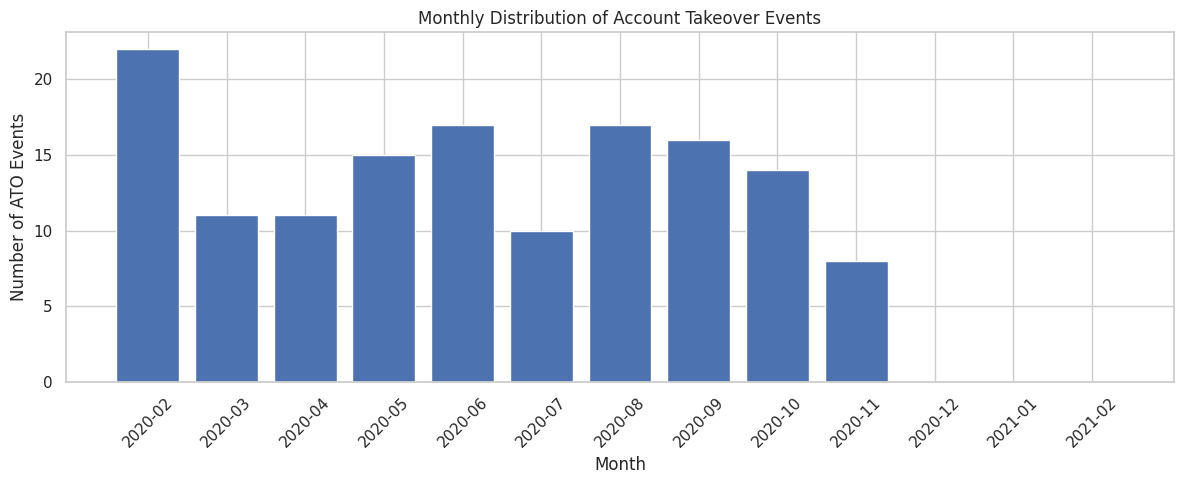

Total ATO events: 141


In [ ]:
import matplotlib.pyplot as plt

# Extract monthly positive ATO events
monthly_ato = (
    original_monthly[
        original_monthly[TARGET_COLUMN] == True
    ]
    .set_index("Month")["Count"]
    .reindex(
        pd.period_range(
            start="2020-02",
            end="2021-02",
            freq="M"
        ),
        fill_value=0
    )
)

# Plot monthly ATO events
plt.figure(figsize=(12, 5))

plt.bar(
    monthly_ato.index.astype(str),
    monthly_ato.values
)

plt.title("Monthly Distribution of Account Takeover Events")
plt.xlabel("Month")
plt.ylabel("Number of ATO Events")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Display total number of ATO events
print("Total ATO events:", monthly_ato.sum())

#### 4.7.2 Calculate monthly event counts in the sampled dataset サンプルデータの月別集計

In [ ]:
# Calculate monthly event counts in the sampled dataset サンプルデータの月別集計

df["Month"] = df["Login Timestamp"].dt.to_period("M")

sampled_monthly = (
    df.groupby(["Month", TARGET_COLUMN])
      .size()
      .reset_index(name="Count")
)

print("Sampled monthly distribution:")
display(sampled_monthly)

Sampled monthly distribution:


,Month,Is Account Takeover,Count
0,2020-02,False,12739
1,2020-02,True,22
2,2020-03,False,14248
3,2020-03,True,11
4,2020-04,False,13838
5,2020-04,True,11
6,2020-05,False,13894
7,2020-05,True,15
8,2020-06,False,13958
9,2020-06,True,17


#### 4.7.3 Monthly Distribution Comparison

In [ ]:
# Compare monthly event counts in the original and sampled datasets

monthly_comparison = original_monthly.merge(
    sampled_monthly,
    on=["Month", TARGET_COLUMN],
    how="outer",
    suffixes=("_Original", "_Sampled")
).fillna(0)

monthly_comparison = monthly_comparison.rename(
    columns={
        "Count_Original": "Original Count",
        "Count_Sampled": "Sampled Count"
    }
)

display(monthly_comparison)

,Month,Is Account Takeover,Original Count,Sampled Count
0,2020-02,False,2004428,12739
1,2020-02,True,22,22
2,2020-03,False,2214812,14248
3,2020-03,True,11,11
4,2020-04,False,2173300,13838
5,2020-04,True,11,11
6,2020-05,False,2158068,13894
7,2020-05,True,15,15
8,2020-06,False,2185584,13958
9,2020-06,True,17,17


### 4.8 Data Preparation Summary

The data preparation process has been completed successfully.

The final sampled dataset contains 200,141 login events and 6 columns.

Key results:

- All 141 positive Account Takeover (ATO) events were retained.
- 200,000 negative events were randomly sampled.
- Missing values were handled.
- Duplicate records were not found.
- Data types were verified and standardized.
- Device type categories were standardized.
- Login events were sorted chronologically.
- The sampled dataset covers almost the entire original observation period, from February 3, 2020, to February 28, 2021.

The prepared dataset is now ready for feature engineering.

The target variable, `Is Account Takeover`, will be kept separate from the model input features and used only for evaluation.

## 5 - Feature Engineering

Feature engineering is the process of transforming raw data into meaningful features that can help a machine learning model identify patterns and anomalies.

In this section, we will create features from login timestamps and prepare categorical and numerical variables for anomaly detection.

The following principles will guide feature selection:

- Extract time-based features from `Login Timestamp`.
- Convert login outcomes into numerical values.
- Retain relevant contextual information such as `Country` and `Device Type`.
- Exclude raw identifiers and timestamps from the model input.
- Keep `Is Account Takeover` separate from the input features because it is reserved for model evaluation.

These steps help ensure that the model uses meaningful behavioral and contextual information without directly accessing the evaluation labels.

### 5.2 Create Time-Based Features

Create temporal features of login behavior from the `login timestamp`.

The five features to be created are as follows:

| Feature | Meaning |
| :--- | :--- |
| `Login Hour` | Login hour (0 to 23 hours)|
| `Login Day` | Day of the month |
| `Login Day of Week` | Day of the week (Monday = 0, Sunday = 6) |
| `Login Month` | Login month (1 to 12) |
| `Is Weekend` | 1 if Saturday or Sunday, otherwise 0 |

In [ ]:
# Extract time-based features
df["Login Hour"] = df["Login Timestamp"].dt.hour

df["Login Day"] = df["Login Timestamp"].dt.day

df["Login Day of Week"] = (
    df["Login Timestamp"].dt.dayofweek
)

df["Login Month"] = df["Login Timestamp"].dt.month

df["Is Weekend"] = (
    df["Login Day of Week"] >= 5
).astype(int)

# Display the new features
display(
    df[
        [
            "Login Timestamp",
            "Login Hour",
            "Login Day",
            "Login Day of Week",
            "Login Month",
            "Is Weekend"
        ]
    ].head()
)

,Login Timestamp,Login Hour,Login Day,Login Day of Week,Login Month,Is Weekend
0,2020-02-03 12:45:35.586,12,3,0,2,0
1,2020-02-03 12:45:56.814,12,3,0,2,0
2,2020-02-03 12:46:25.327,12,3,0,2,0
3,2020-02-03 12:47:56.608,12,3,0,2,0
4,2020-02-03 12:47:59.681,12,3,0,2,0


### 5.3 Login Outcome Encoding

The `Login Successful` column indicates whether a login attempt was successful.

Although this column is stored as a Boolean variable, we convert it into an integer representation for consistency during feature preprocessing.

- `True` is encoded as 1.
- `False` is encoded as 0.

This feature may help the anomaly detection model identify unusual login patterns. However, a failed login does not necessarily indicate malicious activity.

In [ ]:
# Convert login outcome from Boolean to integer
df["Login Successful"] = (
    df["Login Successful"].astype(int)
)

# Check the conversion
print("Data type:", df["Login Successful"].dtype)

print("\nLogin outcome distribution:")
print(df["Login Successful"].value_counts())

print("\nFirst five values:")
print(df["Login Successful"].head())

Data type: int64

Login outcome distribution:
Login Successful
0    120066
1     80075
Name: count, dtype: int64

First five values:
0    0
1    0
2    0
3    1
4    0
Name: Login Successful, dtype: int64


### 5.4 Categorical Feature Preparation

The `Country` and `Device Type` columns contain categorical information.

These features may provide useful contextual information for identifying unusual login behavior.

Before encoding them, we inspect their unique values and distributions.

Categorical encoding will be performed later in the data preprocessing section.

In [ ]:
# Inspect categorical features
categorical_columns = ["Country", "Device Type"]

for column in categorical_columns:
    print(f"\n{column} - Unique values:")
    print(df[column].nunique())

    print(f"\n{column} - Value counts:")
    print(df[column].value_counts(dropna=False))


Country - Unique values:
183

Country - Value counts:
Country
NO    84536
US    55671
RU    10701
BR     7672
DE     5689
      ...  
FO        1
GD        1
LR        1
PF        1
DZ        1
Name: count, Length: 183, dtype: int64

Device Type - Unique values:
5

Device Type - Value counts:
Device Type
mobile     125902
desktop     50972
bot         12805
unknown      5424
tablet       5038
Name: count, dtype: int64


#### 5.4.1 Device Type Distribution

We visualize the distribution of device types to understand the composition of login events in the sampled dataset.

The bar chart shows the number of login events for each device category.

This visualization helps identify the most frequently used device types and categories with relatively low representation.

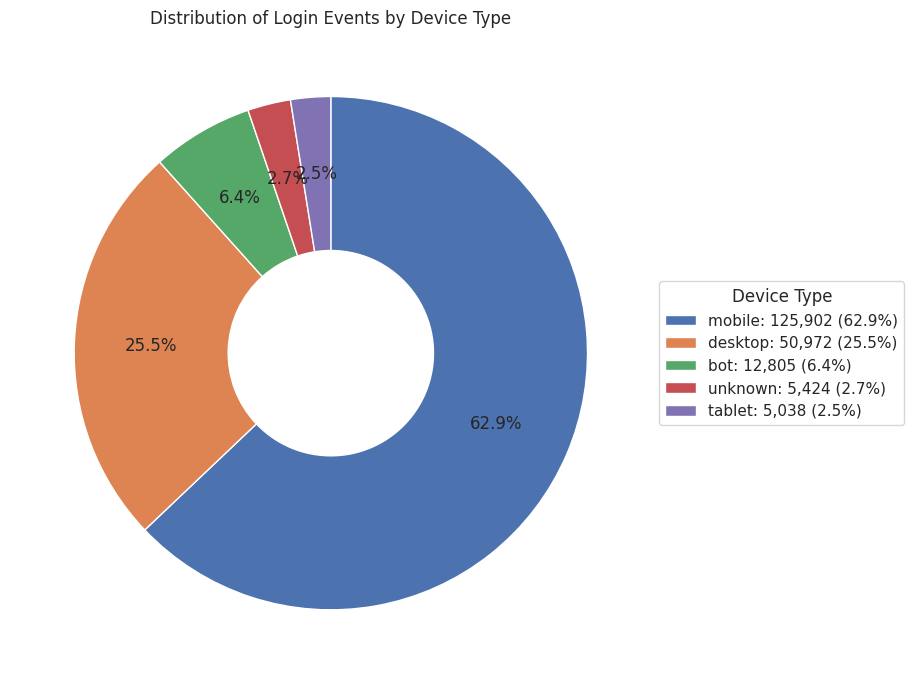

In [ ]:
# Calculate device type counts
device_counts = df["Device Type"].value_counts()

# Create labels for the legend
legend_labels = [
    f"{device}: {count:,} ({count / device_counts.sum() * 100:.1f}%)"
    for device, count in device_counts.items()
]

# Create the pie chart
plt.figure(figsize=(10, 7))

wedges, texts, autotexts = plt.pie(
    device_counts.values,
    labels=None,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
    pctdistance=0.70,
    wedgeprops=dict(width=0.6, edgecolor='white')
)

# Add legend outside the pie chart
plt.legend(
    wedges,
    legend_labels,
    title="Device Type",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.title("Distribution of Login Events by Device Type")
plt.tight_layout()
plt.show()

**Interpretation:**

The device type distribution shows that mobile devices account for the largest proportion of login events, with 125,902 events (approximately 62.9%). Desktop devices are the second most common category, with 50,972 events (approximately 25.5%).

Bot activity represents approximately 6.4% of the sampled events, while unknown and tablet devices account for approximately 2.7% and 2.5%, respectively.

These results indicate that most login events in the sampled dataset originate from mobile and desktop devices.

However, the presence of a bot or an unknown device type does not necessarily indicate malicious activity. These categories should be interpreted as contextual features rather than direct indicators of an account takeover.

#### 5.4.2 Country Distribution

The dataset contains 183 unique country codes. To make the distribution easier to interpret, we visualize the 10 countries with the highest number of login events.

This visualization helps identify the countries that contribute most to the sampled dataset.

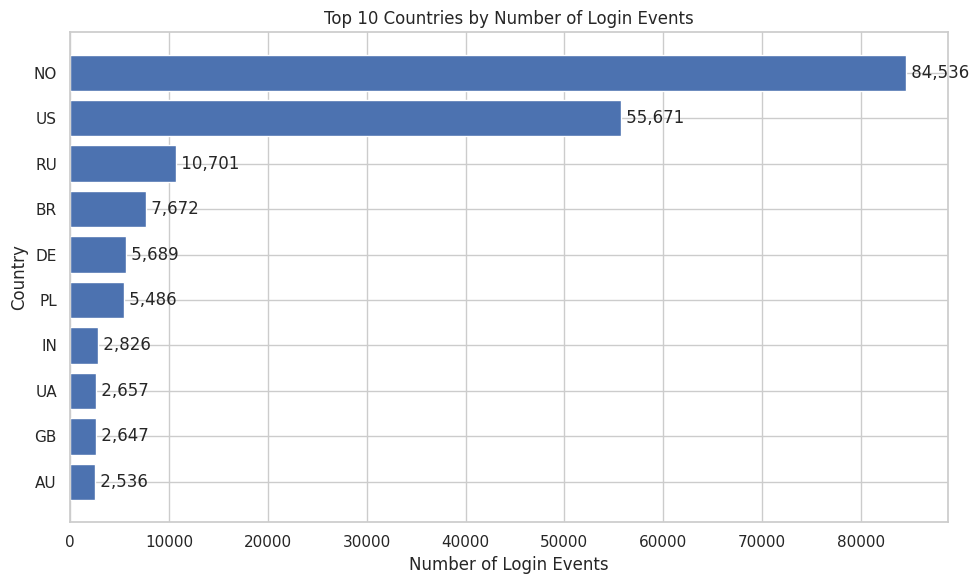

In [ ]:
# Count login events by country
country_counts = df["Country"].value_counts()

# Select the top 10 countries
top_10_countries = country_counts.head(10)

# Create a horizontal bar chart
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_countries.index[::-1],
    top_10_countries.values[::-1]
)

plt.title("Top 10 Countries by Number of Login Events")
plt.xlabel("Number of Login Events")
plt.ylabel("Country")

# Display values next to each bar
for i, value in enumerate(top_10_countries.values[::-1]):
    plt.text(value, i, f" {value:,}", va="center")

plt.tight_layout()
plt.show()

**Interpretation**:

The country distribution shows that login events are concentrated in a relatively small number of countries.

Norway (NO) has the highest number of login events, with 84,536 records, followed by the United States (US) with 55,671 records. Russia (RU) and Brazil (BR) are also among the countries with the highest event counts.

These results indicate that the sampled dataset is geographically imbalanced, with a large proportion of login events originating from a few country codes.

Country information may provide useful context for identifying unusual login behavior. For example, a login from a country that differs from a user's usual login locations could be worth investigating.

However, a country with a high or low number of login events should not automatically be considered suspicious. Geographic differences alone do not establish malicious activity.



---



### 5.5 Review Engineered Features

In [ ]:
# Review the engineered features
engineered_columns = [
    "Login Hour",
    "Login Day",
    "Login Day of Week",
    "Login Month",
    "Is Weekend",
    "Login Successful",
    "Country",
    "Device Type"
]

display(df[engineered_columns].head())

print("\nEngineered feature data types:")
print(df[engineered_columns].dtypes)

print("\nDataset shape:", df.shape)

,Login Hour,Login Day,Login Day of Week,Login Month,Is Weekend,Login Successful,Country,Device Type
0,12,3,0,2,0,0,NO,mobile
1,12,3,0,2,0,0,NO,mobile
2,12,3,0,2,0,0,NO,desktop
3,12,3,0,2,0,1,NO,desktop
4,12,3,0,2,0,0,US,mobile



Engineered feature data types:
Login Hour            int32
Login Day             int32
Login Day of Week     int32
Login Month           int32
Is Weekend            int64
Login Successful      int64
Country              object
Device Type          object
dtype: object

Dataset shape: (200141, 12)
